In [10]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector

In [11]:
# Create a 2-qubit quantum circuit

qc = QuantumCircuit(2)

In [12]:
# Create uniform superposition

qc.h(0)
qc.h(1)

qc.barrier()

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=2, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>, <Qubit register=(2, "q"), index=1>), clbits=())

In [13]:
# Oracle (to search for |10>)

qc.x(1) # Apply X gate to qubit 0 to flip |0> to |1>
qc.cz(1, 0) # Apply controlled-Z gate to flip the phase of |10>
qc.x(1) # Apply X gate to qubit 0 to flip |1> back to |0>

qc.barrier()

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=2, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>, <Qubit register=(2, "q"), index=1>), clbits=())

In [14]:
# Grover diffuser

qc.h(0)     # Apply Hadamard gate to qubit 0 to create superposition
qc.h(1)     # Apply Hadamard gate to qubit 1 to create superposition

qc.x(0)     # Apply X gate to qubit 0 to flip |0> to |1>
qc.x(1)     # Apply X gate to qubit 1 to flip |0> to |1>

qc.cz(0, 1)     # Apply controlled-Z gate to flip the phase of |11>

qc.x(0)     # Apply X gate to qubit 0 to flip |1> back to |0>
qc.x(1)     # Apply X gate to qubit 1 to flip |1> back to |0>

qc.h(0)     # Apply Hadamard gate to qubit 0 to create superposition
qc.h(1)     # Apply Hadamard gate to qubit 1 to create superposition

qc.barrier()

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=2, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>, <Qubit register=(2, "q"), index=1>), clbits=())

In [15]:
# Statevector

state = Statevector.from_instruction(qc)

print("\nStatevector:")
print(state)


Statevector:
Statevector([-9.52420783e-18+0.j, -1.00000000e+00+0.j, -1.26316153e-34+0.j,
             -2.36158002e-17+0.j],
            dims=(2, 2))


In [16]:
# Measure

qc.measure_all()

simulator = AerSimulator()

job = simulator.run(qc, shots=1024)

result = job.result()

counts = result.get_counts()

print("\nMeasurement results:")
print(counts)


Measurement results:
{'01': 1024}


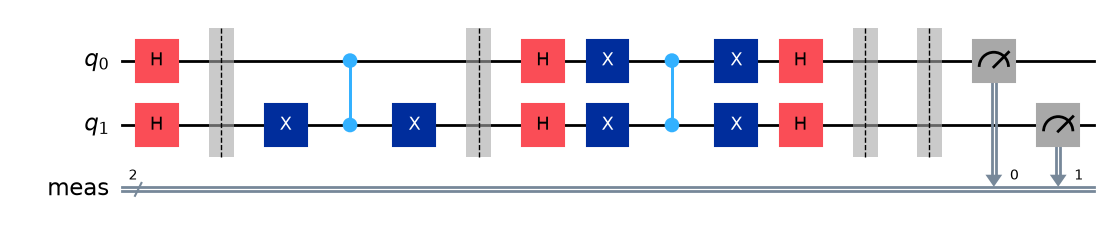

In [17]:
# Display circuit

qc.draw('mpl')